# Assignment 3: ARIMA vs. Prophet

**Goal:** forecast the last 28 days (2016-03-28 to 2016-04-24) of `CA_1` total sales with seasonal ARIMA(1,1,1)(1,1,1,7) and Prophet; compare MAE, RMSE, MAPE, WAPE.

In [1]:
from pathlib import Path
import importlib.util
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

if importlib.util.find_spec("prophet") is None:
    raise ImportError(
        "Prophet is required for this assignment. Install it in this notebook's Python environment "
        "(for example, run %pip install prophet in a separate notebook cell), then restart the kernel."
    )
from prophet import Prophet

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 12)

search_roots = [Path.cwd(), *Path.cwd().parents]
DATA_DIR = next(
    (root / "m5-forecasting-accuracy" for root in search_roots
     if (root / "m5-forecasting-accuracy").is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find m5-forecasting-accuracy. Run from the workspace or its notebooks folder."
    )

SALES_PATH = DATA_DIR / "sales_train_validation.csv"
CALENDAR_PATH = DATA_DIR / "calendar.csv"
STORE_ID = "CA_1"
HORIZON = 28
ARIMA_ORDER = (1, 1, 1)
ARIMA_SEASONAL_ORDER = (1, 1, 1, 7)
print(f"Data folder: {DATA_DIR}")

Importing plotly failed. Interactive plots will not work.


Data folder: c:\Users\mandabhushan\OneDrive - Nagarro\Documents\D\Learnings\Projects\Time_series\m5-forecasting-accuracy


## Data and split

In [2]:
header = pd.read_csv(SALES_PATH, nrows=0).columns.tolist()
day_cols = [column for column in header if column.startswith("d_")]
if not day_cols:
    raise ValueError("No daily sales columns beginning with 'd_' were found.")

store_totals = None
for chunk in pd.read_csv(SALES_PATH, usecols=["store_id"] + day_cols, chunksize=512):
    store_rows = chunk.loc[chunk["store_id"] == STORE_ID, day_cols]
    if not store_rows.empty:
        chunk_totals = store_rows.sum(axis=0)
        store_totals = chunk_totals if store_totals is None else store_totals.add(chunk_totals)
if store_totals is None:
    raise ValueError(f"Store {STORE_ID!r} was not found in the sales file.")

calendar = pd.read_csv(CALENDAR_PATH, usecols=["d", "date"])
calendar["date"] = pd.to_datetime(calendar["date"])
sales = pd.DataFrame({"d": day_cols, "sales": store_totals.reindex(day_cols).to_numpy()})
sales = sales.merge(calendar, on="d", how="left", validate="one_to_one")
sales = sales.sort_values("date").set_index("date")
if sales.index.hasnans or sales["sales"].isna().any():
    raise ValueError("Sales contain missing dates or values after joining to the calendar.")
if not sales.index.is_unique or not sales.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all():
    raise ValueError("Expected one consecutive daily observation per date.")

y = sales["sales"].astype(float).rename("sales")
if len(y) <= HORIZON:
    raise ValueError(f"Need more than {HORIZON} daily observations to create the requested holdout.")
train = y.iloc[:-HORIZON]
test = y.iloc[-HORIZON:]
print(f"Series: {STORE_ID} total daily sales")
print(f"Training: {train.index.min().date()} through {train.index.max().date()} ({len(train):,} days)")
print(f"Holdout:  {test.index.min().date()} through {test.index.max().date()} ({len(test):,} days)")
display(pd.DataFrame({"train": [len(train)], "holdout": [len(test)], "zero actuals in holdout": [(test == 0).sum()]}))

Series: CA_1 total daily sales
Training: 2011-01-29 through 2016-03-27 (1,885 days)
Holdout:  2016-03-28 through 2016-04-24 (28 days)


,train,holdout,zero actuals in holdout
0,1885,28,0


## Seasonal ARIMA

In [3]:
with warnings.catch_warnings(record=True) as arima_warnings:
    warnings.simplefilter("always")
    arima_model = ARIMA(
        train,
        order=ARIMA_ORDER,
        seasonal_order=ARIMA_SEASONAL_ORDER,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=HORIZON)
arima_forecast = pd.Series(np.asarray(arima_forecast), index=test.index, name="ARIMA")
print(arima_fit.summary())
if arima_warnings:
    print("ARIMA warnings:")
    for warning in arima_warnings:
        print(f"- {warning.message}")

                                    SARIMAX Results                                    
Dep. Variable:                           sales   No. Observations:                 1885
Model:             ARIMA(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -13999.824
Date:                         Tue, 17 Nov 2026   AIC                          28009.648
Time:                                 16:14:45   BIC                          28037.312
Sample:                             01-29-2011   HQIC                         28019.841
                                  - 03-27-2016                                         
Covariance Type:                           opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3501      0.015     24.092      0.000       0.322       0.379
ma.L1         -0.9603      0.008   -120.524      0.000     

## Prophet

In [4]:
prophet_train = pd.DataFrame({"ds": train.index, "y": train.to_numpy()})
prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.80,
)
prophet_model.fit(prophet_train)

future = pd.DataFrame({"ds": test.index})
prophet_output = prophet_model.predict(future)
prophet_forecast = pd.Series(
    prophet_output["yhat"].to_numpy(), index=test.index, name="Prophet"
)
display(prophet_output[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())

16:14:46 - cmdstanpy - INFO - Chain [1] start processing
16:14:47 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
0,2016-03-28,4358.884855,3747.948354,4959.856595
1,2016-03-29,3926.585744,3294.614620,4531.824011
2,2016-03-30,3844.123803,3284.568211,4411.086604
3,2016-03-31,3888.030012,3249.973634,4465.415492
4,2016-04-01,4554.181385,3987.527521,5178.948137


## Error comparison

In [5]:
forecasts = pd.concat([arima_forecast, prophet_forecast], axis=1)
if not forecasts.index.equals(test.index):
    raise ValueError("Model forecasts are not aligned to the same holdout dates.")
if forecasts.isna().any().any():
    raise ValueError("A model produced missing forecast values.")

def forecast_metrics(actual: pd.Series, predicted: pd.Series) -> dict:
    errors = predicted - actual
    nonzero = actual != 0
    mape = (
        float((errors[nonzero].abs() / actual[nonzero].abs()).mean() * 100)
        if nonzero.any()
        else np.nan
    )
    actual_total = float(actual.abs().sum())
    wape = float(errors.abs().sum() / actual_total * 100) if actual_total > 0 else np.nan
    return {
        "MAE (units)": float(errors.abs().mean()),
        "RMSE (units)": float(np.sqrt(np.mean(np.square(errors)))),
        "MAPE on non-zero actuals (%)": mape,
        "WAPE (%)": wape,
    }

metrics = pd.DataFrame(
    {name: forecast_metrics(test, forecasts[name]) for name in forecasts.columns}
).T
print(f"Zero actuals: {(test == 0).sum()} of {len(test)} holdout days")
display(metrics.sort_values("MAE (units)"))

Zero actuals: 0 of 28 holdout days


,MAE (units),RMSE (units),MAPE on non-zero actuals (%),WAPE (%)
ARIMA,271.770893,359.033049,5.611250,5.947079
Prophet,275.204901,336.895299,6.021731,6.022224


## Forecast plot

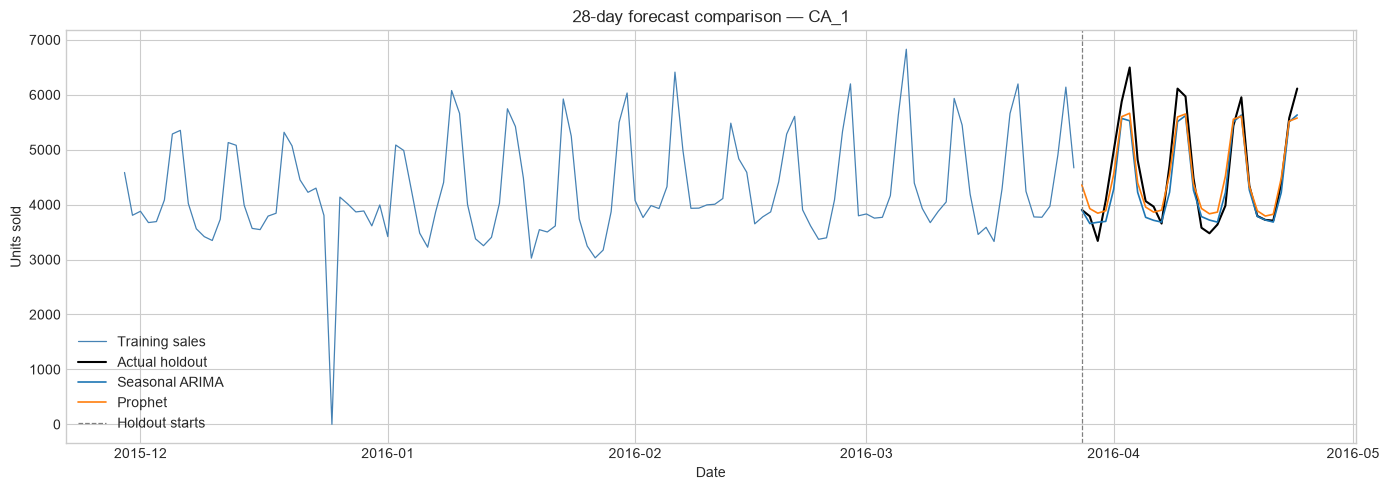

In [6]:
context = train.iloc[-120:]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(context.index, context, label="Training sales", color="steelblue", linewidth=0.9)
ax.plot(test.index, test, label="Actual holdout", color="black", linewidth=1.5)
ax.plot(arima_forecast.index, arima_forecast, label="Seasonal ARIMA", linewidth=1.2)
ax.plot(prophet_forecast.index, prophet_forecast, label="Prophet", linewidth=1.2)
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.9, label="Holdout starts")
ax.set(title=f"28-day forecast comparison — {STORE_ID}", xlabel="Date", ylabel="Units sold")
ax.legend()
plt.tight_layout()
plt.show()

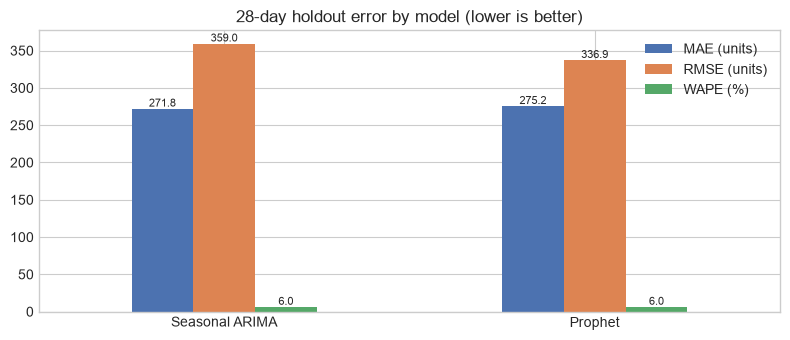

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

res = pd.DataFrame({"Seasonal ARIMA": [271.77, 359.03, 5.95], "Prophet": [275.20, 336.90, 6.02]},
                   index=["MAE (units)", "RMSE (units)", "WAPE (%)"])
ax = res.T.plot(kind="bar", figsize=(8, 3.5), color=["#4c72b0", "#dd8452", "#55a868"], rot=0)
ax.set(title="28-day holdout error by model (lower is better)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.show()


## Conclusion

- The models are close: ARIMA is better on MAE (272 vs 275), MAPE and WAPE (5.95% vs 6.02%); Prophet is better on RMSE (337 vs 359).
- Neither wins on every metric.
- **Limit:** one store, one holdout, fixed parameters, no price/event regressors.